## 1. Import Necessary Libraries

In [1]:
!pip install lightgbm

     ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
     --- ------------------------------------ 0.1/1.4 MB 3.6 MB/s eta 0:00:01
     ---------------- ----------------------- 0.6/1.4 MB 7.0 MB/s eta 0:00:01
     ---------------------------------------  1.4/1.4 MB 10.7 MB/s eta 0:00:01
     ---------------------------------------- 1.4/1.4 MB 9.6 MB/s eta 0:00:00



[notice] A new release of pip is available: 23.0.1 -> 26.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

from sklearn.ensemble import AdaBoostClassifier,GradientBoostingClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

from sklearn.metrics import accuracy_score,precision_score,recall_score,confusion_matrix

import warnings
warnings.filterwarnings("ignore")

## 2. Import Dataset

In [3]:
credit_card_data = pd.read_csv("credit_card_clean.csv")
credit_card_data

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,1,20000.0,female,university,married,24,2,2,-1,-1,-2,-2,3913.0,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,female,university,single,26,-1,2,0,0,0,2,2682.0,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,female,university,single,34,0,0,0,0,0,0,29239.0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,female,university,married,37,0,0,0,0,0,0,46990.0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,male,university,married,57,-1,0,-1,0,0,0,8617.0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,29996,220000.0,male,highschool,married,39,0,0,0,0,0,0,188948.0,192815.0,208365.0,88004.0,31237.0,15980.0,8500.0,20000.0,5003.0,3047.0,5000.0,1000.0,0
29996,29997,150000.0,male,highschool,single,43,-1,-1,-1,-1,0,0,1683.0,1828.0,3502.0,8979.0,5190.0,0.0,1837.0,3526.0,8998.0,129.0,0.0,0.0,0
29997,29998,30000.0,male,university,single,37,4,3,2,-1,0,0,3565.0,3356.0,2758.0,20878.0,20582.0,19357.0,0.0,0.0,22000.0,4200.0,2000.0,3100.0,1
29998,29999,80000.0,male,highschool,married,41,1,-1,0,0,0,-1,-1645.0,78379.0,76304.0,52774.0,11855.0,48944.0,85900.0,3409.0,1178.0,1926.0,52964.0,1804.0,1


## 3. Data Understanding

### Exploring the variable
* ID : ID of each client

* LIMIT_BAL: Amount of given credit in NT dollars (includes individual and family/supplementary credit)

* SEX: Gender (1=male, 2=female)

* EDUCATION: (1=graduate school, 2=university, 3=high school, 4=others, 5=unknown, 6=unknown)

* MARRIAGE: Marital status (1=married, 2=single, 3=others)

* AGE: Age in years

* PAY_1: Repayment status in September, 2005 (-2 = No consumption, -1 = paid in full, 0 = use of revolving credit (paid minimum only), 1 = payment delay for one month, 2 = payment delay for two months, ... 8 = payment delay for eight months, 9 = payment delay for nine months and above)

* PAY_2: Repayment status in August, 2005 (scale same as above)

* PAY_3: Repayment status in July, 2005 (scale same as above)

* PAY_4: Repayment status in June, 2005 (scale same as above)

* PAY_5: Repayment status in May, 2005 (scale same as above)

* PAY_6: Repayment status in April, 2005 (scale same as above)

* BILL_AMT1: Amount of bill statement in September, 2005 (NT dollar)

* BILL_AMT2: Amount of bill statement in August, 2005 (NT dollar)

* BILL_AMT3: Amount of bill statement in July, 2005 (NT dollar)

* BILL_AMT4: Amount of bill statement in June, 2005 (NT dollar)

* BILL_AMT5: Amount of bill statement in May, 2005 (NT dollar)

* BILL_AMT6: Amount of bill statement in April, 2005 (NT dollar)

* PAY_AMT1: Amount of previous payment in September, 2005 (NT dollar)

* PAY_AMT2: Amount of previous payment in August, 2005 (NT dollar)

* PAY_AMT3: Amount of previous payment in July, 2005 (NT dollar)

* PAY_AMT4: Amount of previous payment in June, 2005 (NT dollar)

* PAY_AMT5: Amount of previous payment in May, 2005 (NT dollar)

* PAY_AMT6: Amount of previous payment in April, 2005 (NT dollar)

#### Target variable
default.payment.next.month: Default payment (1=yes, 0=no)

###### Note: NT is Taiwain Dollars

## 3. Data Undetstanding

In [4]:
 credit_card_data.isna().sum()

ID           0
LIMIT_BAL    0
SEX          0
EDUCATION    0
MARRIAGE     0
AGE          0
PAY_1        0
PAY_2        0
PAY_3        0
PAY_4        0
PAY_5        0
PAY_6        0
BILL_AMT1    0
BILL_AMT2    0
BILL_AMT3    0
BILL_AMT4    0
BILL_AMT5    0
BILL_AMT6    0
PAY_AMT1     0
PAY_AMT2     0
PAY_AMT3     0
PAY_AMT4     0
PAY_AMT5     0
PAY_AMT6     0
DEFAULT      0
dtype: int64

In [5]:
credit_card_data.dtypes

ID             int64
LIMIT_BAL    float64
SEX           object
EDUCATION     object
MARRIAGE      object
AGE            int64
PAY_1          int64
PAY_2          int64
PAY_3          int64
PAY_4          int64
PAY_5          int64
PAY_6          int64
BILL_AMT1    float64
BILL_AMT2    float64
BILL_AMT3    float64
BILL_AMT4    float64
BILL_AMT5    float64
BILL_AMT6    float64
PAY_AMT1     float64
PAY_AMT2     float64
PAY_AMT3     float64
PAY_AMT4     float64
PAY_AMT5     float64
PAY_AMT6     float64
DEFAULT        int64
dtype: object

In [6]:
credit_card_data.shape

(30000, 25)

## 4. Data Preparation

In [7]:
del credit_card_data["ID"]

In [8]:
credit_card_data

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,20000.0,female,university,married,24,2,2,-1,-1,-2,-2,3913.0,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,120000.0,female,university,single,26,-1,2,0,0,0,2,2682.0,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,90000.0,female,university,single,34,0,0,0,0,0,0,29239.0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,50000.0,female,university,married,37,0,0,0,0,0,0,46990.0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,50000.0,male,university,married,57,-1,0,-1,0,0,0,8617.0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,220000.0,male,highschool,married,39,0,0,0,0,0,0,188948.0,192815.0,208365.0,88004.0,31237.0,15980.0,8500.0,20000.0,5003.0,3047.0,5000.0,1000.0,0
29996,150000.0,male,highschool,single,43,-1,-1,-1,-1,0,0,1683.0,1828.0,3502.0,8979.0,5190.0,0.0,1837.0,3526.0,8998.0,129.0,0.0,0.0,0
29997,30000.0,male,university,single,37,4,3,2,-1,0,0,3565.0,3356.0,2758.0,20878.0,20582.0,19357.0,0.0,0.0,22000.0,4200.0,2000.0,3100.0,1
29998,80000.0,male,highschool,married,41,1,-1,0,0,0,-1,-1645.0,78379.0,76304.0,52774.0,11855.0,48944.0,85900.0,3409.0,1178.0,1926.0,52964.0,1804.0,1


In [12]:
le = LabelEncoder()
credit_card_data["SEX"]= le.fit_transform(credit_card_data["SEX"])
credit_card_data["EDUCATION"] = le.fit_transform(credit_card_data["EDUCATION"])
credit_card_data["MARRIAGE"] = le.fit_transform(credit_card_data["MARRIAGE"])
credit_card_data

,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_1,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6,BILL_AMT1,BILL_AMT2,BILL_AMT3,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,DEFAULT
0,20000.0,0,3,0,24,2,2,-1,-1,-2,-2,3913.0,3102.0,689.0,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,120000.0,0,3,2,26,-1,2,0,0,0,2,2682.0,1725.0,2682.0,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,90000.0,0,3,2,34,0,0,0,0,0,0,29239.0,14027.0,13559.0,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,50000.0,0,3,0,37,0,0,0,0,0,0,46990.0,48233.0,49291.0,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,50000.0,1,3,0,57,-1,0,-1,0,0,0,8617.0,5670.0,35835.0,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
29995,220000.0,1,1,0,39,0,0,0,0,0,0,188948.0,192815.0,208365.0,88004.0,31237.0,15980.0,8500.0,20000.0,5003.0,3047.0,5000.0,1000.0,0
29996,150000.0,1,1,2,43,-1,-1,-1,-1,0,0,1683.0,1828.0,3502.0,8979.0,5190.0,0.0,1837.0,3526.0,8998.0,129.0,0.0,0.0,0
29997,30000.0,1,3,2,37,4,3,2,-1,0,0,3565.0,3356.0,2758.0,20878.0,20582.0,19357.0,0.0,0.0,22000.0,4200.0,2000.0,3100.0,1
29998,80000.0,1,1,0,41,1,-1,0,0,0,-1,-1645.0,78379.0,76304.0,52774.0,11855.0,48944.0,85900.0,3409.0,1178.0,1926.0,52964.0,1804.0,1


In [13]:
credit_card_data.dtypes

LIMIT_BAL    float64
SEX            int64
EDUCATION      int64
MARRIAGE       int64
AGE            int64
PAY_1          int64
PAY_2          int64
PAY_3          int64
PAY_4          int64
PAY_5          int64
PAY_6          int64
BILL_AMT1    float64
BILL_AMT2    float64
BILL_AMT3    float64
BILL_AMT4    float64
BILL_AMT5    float64
BILL_AMT6    float64
PAY_AMT1     float64
PAY_AMT2     float64
PAY_AMT3     float64
PAY_AMT4     float64
PAY_AMT5     float64
PAY_AMT6     float64
DEFAULT        int64
dtype: object

## 5. Model Building

In [15]:
X = credit_card_data.drop("DEFAULT", axis = 1)
y = credit_card_data["DEFAULT"]

In [16]:
X.shape,y.shape

((30000, 23), (30000,))

In [17]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size = 0.20, random_state = 123, shuffle = True, stratify = y)

In [19]:
X_train.shape,y_train.shape

((24000, 23), (24000,))

In [20]:
X_test.shape,y_test.shape

((6000, 23), (6000,))

## 6. Model Training

### Training Time Analysis

In [22]:
adb_classifier = AdaBoostClassifier()
gb_classifier = GradientBoostingClassifier(n_estimators = 50)
xgb_classifier = XGBClassifier(n_estimators = 50)
lgbm_classifier = LGBMClassifier(n_estimators = 50)

In [23]:
%%time
adb_classifier.fit(X_train,y_train)

CPU times: total: 2.2 s
Wall time: 2.39 s


,estimator,None
,n_estimators,50
,learning_rate,1.0
,algorithm,'deprecated'
,random_state,None


In [27]:
%%time
gb_classifier.fit(X_train,y_train)

CPU times: total: 5.02 s
Wall time: 5.33 s


,loss,'log_loss'
,learning_rate,0.1
,n_estimators,50
,subsample,1.0
,criterion,'friedman_mse'
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_depth,3
,min_impurity_decrease,0.0
,init,None


In [28]:
%%time
xgb_classifier.fit(X_train,y_train)

CPU times: total: 578 ms
Wall time: 198 ms


,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,False
,eval_metric,None


In [30]:
%%time
lgbm_classifier.fit(X_train,y_train)

[LightGBM] [Info] Number of positive: 5309, number of negative: 18691
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000857 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3259
[LightGBM] [Info] Number of data points in the train set: 24000, number of used features: 23
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.221208 -> initscore=-1.258639
[LightGBM] [Info] Start training from score -1.258639
CPU times: total: 234 ms
Wall time: 174 ms


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.1
,n_estimators,50
,subsample_for_bin,200000
,objective,None
,class_weight,None
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


## 7. Model Testing

### Testing Time Analysis

In [42]:
y_pred_adb = adb_classifier.predict(X_test)
y_pred_gb = gb_classifier.predict(X_test)
y_pred_xgb = xgb_classifier.predict(X_test)
y_pred_lgbm = lgbm_classifier.predict(X_test)

## 8. Model Evaluation

### Adaboost Evals

In [43]:
print("Accuracy Score: ", round(accuracy_score(y_test,y_pred_adb),4))
print("Precision Score: ", round(precision_score(y_test,y_pred_adb),4))
print("Recall Score: ", round(recall_score(y_test,y_pred_adb),4))
print("Confusion Matrix:\n", confusion_matrix(y_test,y_pred_adb))

Accuracy Score:  0.8218
Precision Score:  0.7048
Recall Score:  0.3346
Confusion Matrix:
 [[4487  186]
 [ 883  444]]


### Gradient Boosting

In [44]:
print("Accuracy Score: ", round(accuracy_score(y_test,y_pred_gb),4))
print("Precision Score: ", round(precision_score(y_test,y_pred_gb),4))
print("Recall Score: ", round(recall_score(y_test,y_pred_gb),4))
print("Confusion Matrix:\n", confusion_matrix(y_test,y_pred_gb))

Accuracy Score:  0.8233
Precision Score:  0.6949
Recall Score:  0.3587
Confusion Matrix:
 [[4464  209]
 [ 851  476]]


## Extreme Gradient Boosting

In [45]:
print("Accuracy Score: ", round(accuracy_score(y_test,y_pred_xgb),4))
print("Precision Score: ", round(precision_score(y_test,y_pred_xgb),4))
print("Recall Score: ", round(recall_score(y_test,y_pred_x gb),4))
print("Confusion Matrix:\n", confusion_matrix(y_test,y_pred_xgb))

Accuracy Score:  0.8185
Precision Score:  0.6617
Recall Score:  0.367
Confusion Matrix:
 [[4424  249]
 [ 840  487]]


## Light Gradient Boosting

In [46]:
print("Accuracy Score: ", round(accuracy_score(y_test,y_pred_lgbm),4))
print("Precision Score: ", round(precision_score(y_test,y_pred_lgbm),4))
print("Recall Score: ", round(recall_score(y_test,y_pred_lgbm),4))
print("Confusion Matrix:\n", confusion_matrix(y_test,y_pred_lgbm))

Accuracy Score:  0.8248
Precision Score:  0.696
Recall Score:  0.3693
Confusion Matrix:
 [[4459  214]
 [ 837  490]]


## Let,s Learn Feature Importance

In [48]:
abd_feature_imp = adb_classifier.feature_importances_
gb_feature_imp = gb_classifier.feature_importances_
xgb_feature_imp = xgb_classifier.feature_importances_
lgbm_feature_imp = lgbm_classifier.feature_importances_

In [57]:
X.columns

Index(['LIMIT_BAL', 'SEX', 'EDUCATION', 'MARRIAGE', 'AGE', 'PAY_1', 'PAY_2',
       'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6', 'BILL_AMT1', 'BILL_AMT2',
       'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6', 'PAY_AMT1',
       'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6'],
      dtype='object')

In [52]:
feature_importance_list = pd.DataFrame(data = { "Features": X.columns,
                                                "Adaboost_Features" : abd_feature_imp,
                                                "GB_Features":gb_feature_imp,
                                                "XGB_Features": xgb_feature_imp,
                                                "LGBM_Feature": lgbm_feature_imp})
feature_importance_list

,Features,Adaboost_Features,GB_Features,XGB_Features,LGBM_Feature
0,LIMIT_BAL,0.057269,0.026852,0.020686,114
1,SEX,0.000000,0.001689,0.014167,22
2,EDUCATION,0.000000,0.002136,0.016912,33
3,MARRIAGE,0.017747,0.002796,0.015742,22
4,AGE,0.000000,0.003232,0.015355,93
5,PAY_1,0.513985,0.655314,0.440396,67
6,PAY_2,0.035080,0.093329,0.090265,32
7,PAY_3,0.052493,0.041462,0.056189,41
8,PAY_4,0.004686,0.016298,0.040710,23
9,PAY_5,0.017710,0.013692,0.035140,26


## Question 1 - Display the Top 10 Features of Adaboost

In [53]:
import seaborn as sns

In [55]:
gbboost_top_features = feature_importance_list.sort_values(by = "GB_Features", ascending = False)
top_10_gb_features = gbboost_top_features.head(10)
top_10_gb_features

,Features,Adaboost_Features,GB_Features,XGB_Features,LGBM_Feature
5,PAY_1,0.513985,0.655314,0.440396,67
6,PAY_2,0.035080,0.093329,0.090265,32
7,PAY_3,0.052493,0.041462,0.056189,41
0,LIMIT_BAL,0.057269,0.026852,0.020686,114
11,BILL_AMT1,0.014796,0.022708,0.021759,133
17,PAY_AMT1,0.087824,0.021428,0.019545,78
19,PAY_AMT3,0.037968,0.020445,0.023774,86
10,PAY_6,0.042327,0.018587,0.034795,42
18,PAY_AMT2,0.064727,0.017985,0.020704,97
8,PAY_4,0.004686,0.016298,0.040710,23


<Axes: xlabel='GB_Features', ylabel='Features'>

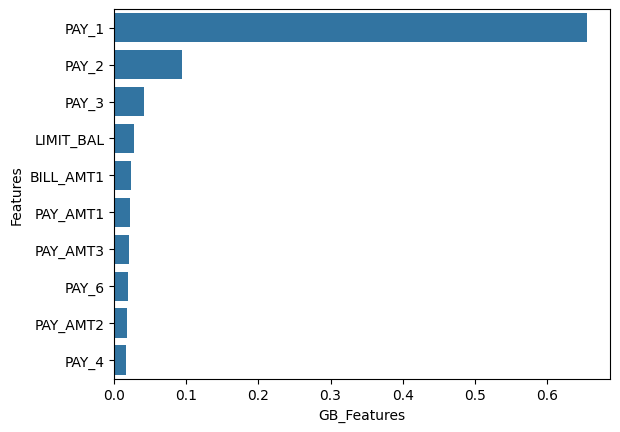

In [56]:
sns.barplot(data = top_10_gb_features, y = "Features", x = "GB_Features")